# Séance 9 — Canevas du projet et préparation de la soutenance

Ce notebook n'est pas un atelier : c'est le **squelette de votre rendu**. Remplacez chaque
section par votre travail. La structure suit l'ordre de la soutenance, ce qui vous évite
de refaire le plan au dernier moment.

---

## Identification

| | |
|---|---|
| Groupe | Groupe 4 — Lucas, Christ, Kouassi |
| Sujet | Garage automobile : interventions d'un réseau de 11 ateliers (`groupe_04_garage`) |
| Question traitée |  |
| Date de soutenance | *jour 5, après-midi* |

> **Format.** 15 minutes de présentation, 10 minutes de questions devant un jury unique.
> Les questions sont posées individuellement : chaque membre du groupe doit pouvoir
> répondre sur l'intégralité du travail, y compris les parties qu'il n'a pas présentées.
> **Dépôt du rendu : jour 5, 13 h 30.**

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name in ('notebooks', 'Notebook') else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  evenements_volumineux.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


> **Votre jeu de données vous est fourni.** Chaque groupe reçoit un domaine différent,
> avec ses propres anomalies : les chiffres, les pièges et les décisions à justifier ne
> sont pas les mêmes d'un groupe à l'autre. Comparer vos *méthodes* entre groupes est
> encouragé ; comparer vos *résultats* ne vous mènera nulle part.

> **Aucun sujet ne dit quelles anomalies son jeu contient.** Les trouver est la première
> partie du travail, et la première chose que le jury vérifiera. Commencez par appliquer
> votre `profile_dataframe` du jour 1 : elle a été écrite pour cela.

---
## 1. Contexte (2 min de présentation)

**À renseigner :** l'origine des données, ce qu'elles décrivent, la période couverte, et la
question à laquelle le jeu préparé doit permettre de répondre.

*Votre texte :*

Les données décrivent l'activité d'un **réseau de garages automobiles** : 17 150 interventions
réalisées dans 11 ateliers (10 sites régionaux et un « site technique » à Orléans) pour
2 400 clients (particuliers, professionnels, associations), sur **deux ans, de janvier 2023 à
décembre 2024**. Chaque intervention porte une prestation (95 au catalogue, regroupées en
5 familles), une durée, le kilométrage du véhicule, le montant facturé, l'origine de la
demande (atelier, concession, assurance) et un statut (facturée, reprise gratuite, en litige).

Les quatre fichiers sont des extractions brutes : une table de faits (`interventions.csv`) et
trois référentiels (`clients.csv`, `prestations.csv`, `ateliers.csv`).

**Objectif du jeu préparé :** permettre d'analyser le chiffre d'affaires par atelier et par
famille de prestation, et de repérer où se concentrent les reprises gratuites et les litiges,
dans un modèle en étoile directement exploitable par un outil de BI.

In [2]:
# Chargement de la source brute. Aucun nettoyage à ce stade :
# on montre l'état initial, c'est lui qui donne sa valeur au travail qui suit.

# Indiquez ici le dossier de VOTRE groupe (voir la fiche Sujets de projet).
GROUP_DIR = ROOT / 'data' / 'projets' / 'groupe_04_garage'   # À ADAPTER

print('Fichiers reçus :')
for path in sorted(GROUP_DIR.glob('*.csv')):
    size_kb = path.stat().st_size / 1024
    print(f'  {path.name:<28} {size_kb:>8.0f} Ko')

# La table principale est la plus volumineuse : les autres sont des référentiels.
# TODO : charger la table de faits et les référentiels, puis afficher un head()
raw_interventions = pd.read_csv(GROUP_DIR / 'interventions.csv')
raw_clients = pd.read_csv(GROUP_DIR / 'clients.csv')
raw_prestations = pd.read_csv(GROUP_DIR / 'prestations.csv')
raw_ateliers = pd.read_csv(GROUP_DIR / 'ateliers.csv')

for name, frame in [('interventions (faits)', raw_interventions), ('clients', raw_clients),
                    ('prestations', raw_prestations), ('ateliers', raw_ateliers)]:
    print(f'{name:<22} {frame.shape}')
raw_interventions.head()

Fichiers reçus :
  ateliers.csv                        1 Ko
  clients.csv                       110 Ko
  interventions.csv                1385 Ko
  prestations.csv                     5 Ko
interventions (faits)  (17150, 10)
clients                (2400, 5)
prestations            (95, 5)
ateliers               (11, 5)


,id_intervention,date_evenement,id_client,id_prestation,id_atelier,duree_heures,km_vehicule,montant_facture_eur,origine,statut
0,ITV0000885,26 Nov 2023,CLI00781,PRS0037,ATL09,1,999999,196.77,assurance,reprise_gratuite
1,ITV0006273,28 Mar 2023,CLI01165,PRS0016,ATL04,9,145987,1671.88,atelier,reprise_gratuite
2,ITV0014510,20-04-2024,CLI00734,PRS0017,ATL07,7,11282,1479.09,CONCESSION,en_litige
3,ITV0004550,12 Mar 2024,CLI01783,PRS0081,ATL06,1,20448,1301.21,atelier,facture
4,ITV0001835,2024-07-09,CLI01482,PRS0038,ATL09,9,180694,457.91,atelier,FACTURE


---
## 2. Diagnostic (3 min)

Appliquez votre fonction `profile_dataframe` de la séance 2, puis **quantifiez** chaque
anomalie. Un diagnostic sans chiffre n'est pas un diagnostic.

In [3]:
import sys
sys.path.insert(0, str(ROOT / 'src'))

# from exploration import profile_dataframe
# profile_dataframe(raw_data, name='...')
from exploration import profile_dataframe

profile_dataframe(raw_interventions, name='interventions')
profile_dataframe(raw_clients, name='clients')
profile_dataframe(raw_prestations, name='prestations')

# Quantification de chaque anomalie, sur les données BRUTES
amount_text = raw_interventions['montant_facture_eur'].astype('string')
nan_eur = amount_text.str.strip().str.lower().eq('nan eur').fillna(False)
age = raw_clients['age']
client_dates = pd.to_datetime(raw_clients.set_index('id_client')['date_creation'])
event_dates = pd.to_datetime(raw_interventions['date_evenement'], format='mixed', dayfirst=True,
                             errors='coerce')
before_creation = event_dates < raw_interventions['id_client'].map(client_dates)
date_patterns = (raw_interventions['date_evenement'].dropna()
                 .str.replace(r'\d', '9', regex=True).str.replace(r'[A-Za-z]{3}', 'Mmm', regex=True))
business_key = ['date_creation', 'segment', 'ville_norm', 'age']
clients_check = raw_clients.assign(ville_norm=raw_clients['ville'].str.strip().str.lower())

n_facts = len(raw_interventions)
anomalies = pd.DataFrame([
    ('doublons stricts', 'toutes', raw_interventions.duplicated().sum(), n_facts),
    ('date absente', 'date_evenement', raw_interventions['date_evenement'].isna().sum(), n_facts),
    ('formats de date différents', 'date_evenement', date_patterns.nunique(), None),
    ('montant en texte « 123,45 EUR »', 'montant_facture_eur',
     (amount_text.str.contains('EUR', na=False) & ~nan_eur).sum(), n_facts),
    ('montant absent (vide ou « nan EUR »)', 'montant_facture_eur',
     raw_interventions['montant_facture_eur'].isna().sum() + nan_eur.sum(), n_facts),
    ('durée négative', 'duree_heures', (raw_interventions['duree_heures'] < 0).sum(), n_facts),
    ('durée de 24 h isolée', 'duree_heures', (raw_interventions['duree_heures'] == 24).sum(), n_facts),
    ('kilométrage 999 999', 'km_vehicule', (raw_interventions['km_vehicule'] == 999_999).sum(), n_facts),
    ('casse / espaces (modalités)', 'origine', raw_interventions['origine'].nunique(), None),
    ('casse / espaces (modalités)', 'statut', raw_interventions['statut'].nunique(), None),
    ('prestation inconnue PRS9999', 'id_prestation',
     (~raw_interventions['id_prestation'].isin(raw_prestations['id_prestation'])).sum(), n_facts),
    ('intervention antérieure à la création du client', 'date_evenement', before_creation.sum(), n_facts),
    ('âge absent', 'age', age.isna().sum(), len(raw_clients)),
    ('âge impossible (< 18 ou > 100)', 'age', ((age < 18) | (age > 100)).sum(), len(raw_clients)),
    ('ville : graphies multiples (modalités)', 'ville', raw_clients['ville'].nunique(), None),
    ('doublon métier client (lignes)', 'clients', clients_check.duplicated(business_key, keep=False).sum(),
     len(raw_clients)),
    ('coût de référence absent', 'cout_reference_eur', raw_prestations['cout_reference_eur'].isna().sum(),
     len(raw_prestations)),
], columns=['anomalie', 'colonne', 'nombre', 'sur'])
anomalies['taux_%'] = (anomalies['nombre'] / anomalies['sur'] * 100).round(2)
print()
print(anomalies.to_string(index=False))

--- interventions ---
dimensions : (17150, 10)
mémoire    : 2 432.6 Ko
doublons   : 150

--- colonnes ---
                      type  manquants  taux_manquants_%  valeurs_distinctes
id_intervention        str          0              0.00               17000
date_evenement         str        342              1.99                6226
id_client              str          0              0.00                2398
id_prestation          str          0              0.00                  96
id_atelier             str          0              0.00                  11
duree_heures         int64          0              0.00                  15
km_vehicule          int64          0              0.00               16269
montant_facture_eur    str       1292              7.53               15048
origine                str          0              0.00                   9
statut                 str          0              0.00                   9

--- statistiques numériques ---
       duree_heures  km_v

### Tableau des anomalies

| Anomalie | Colonne | Ampleur | Gravité | Traitement retenu |
|---|---|---|---|---|
| Doublons stricts | toutes | 150 lignes (0,9 %) | Haute : double le CA des lignes concernées | Suppression, **après** normalisation du texte |
| Dates absentes | `date_evenement` | 342 (2,0 %) | Haute : ligne inexploitable dans le temps | Suppression de la ligne |
| Cinq formats de date | `date_evenement` | 5 formats, ~3 400 lignes chacun | Haute : risque d'inversion jour/mois | `format='mixed', dayfirst=True`, 0 échec de conversion |
| Montants en texte « 519,57 EUR » | `montant_facture_eur` | 1 122 (6,5 %) | Haute : la colonne entière devient du texte | Conversion explicite (`parse_price`) |
| Montants absents, dont 75 « nan EUR » | `montant_facture_eur` | 1 367 (8,0 %) | Haute : mesure principale | **Pas d'imputation**, indicateur `montant_manquant` |
| Durées négatives | `duree_heures` | 28 (0,2 %) | Moyenne : impossible | Mise à vide, la ligne est conservée |
| Durée de 24 h isolée | `duree_heures` | 42 (0,2 %) | Faible : improbable, pas impossible | Conservée et signalée (`duree_suspecte`) |
| Kilométrage 999 999 | `km_vehicule` | 183 (1,1 %) | Moyenne : valeur de remplissage | Mise à vide + indicateur `km_inconnu` |
| Casse et espaces | `origine`, `statut` | 9 modalités au lieu de 3 | Haute : faux groupes en BI | `normalize_text` (identifiants exclus) |
| Prestation inconnue `PRS9999` | `id_prestation` | 87 (0,5 %) | Moyenne : jointure orpheline | Conservée, membre « inconnu » dans la dimension |
| Intervention avant création du client | `date_evenement` | 1 688 (9,8 %) | Moyenne : `date_creation` peu fiable | Signalée en limite, aucune ligne supprimée |
| Âges absents | `age` | 120 (5,0 %) | Moyenne | Médiane par segment + indicateur `age_imputee` |
| Âges impossibles (< 18, > 100, dont 999) | `age` | 131 (5,5 %) | Moyenne : codes de saisie | Mis à vide, puis imputés comme les absents |
| Villes en graphies multiples | `ville` | 40 modalités au lieu de 10 | Moyenne | `normalize_text` |
| Doublon métier client | `clients` | 1 couple | Faible | Signalé, non fusionné (preuve insuffisante) |
| Coût de référence absent | `cout_reference_eur` | 2 prestations | Faible | Médiane de la sous-famille |

---
## 3. Traitements (5 min — la partie la plus longue de la soutenance)

Pour chaque décision, trois éléments sont attendus : **ce que vous avez fait**, **pourquoi**,
et **quelle alternative vous avez écartée**. Le troisième point est celui qui fait la
différence à l'oral.

In [4]:
# Pipeline de nettoyage et de transformation
# TODO
import json
from garage import build_star, clean_clients, clean_interventions, clean_prestations
from joins import check_referential_integrity

GARAGE_DIR = PROCESSED_DIR / 'garage'
STAR_DIR = GARAGE_DIR / 'star'
STAR_DIR.mkdir(parents=True, exist_ok=True)

print('Interventions :')
interventions, log_interventions = clean_interventions(raw_interventions)
print('Clients :')
clients, log_clients = clean_clients(raw_clients)
print('Prestations :')
prestations, log_prestations = clean_prestations(raw_prestations)

# Idempotence : un second passage ne doit rien changer
for function, cleaned in [(clean_interventions, interventions), (clean_clients, clients),
                          (clean_prestations, prestations)]:
    assert function(cleaned, verbose=False)[0].equals(cleaned), f'{function.__name__} non idempotente'
print('\nOK — les trois fonctions sont idempotentes')

# Modèle en étoile et intégrité référentielle
star = build_star(interventions, clients, prestations, raw_ateliers)
check_referential_integrity(star['fact_interventions'], {
    'cle_date': star['dim_date'], 'id_client': star['dim_client'],
    'id_prestation': star['dim_prestation'], 'id_atelier': star['dim_atelier']})

# Export
interventions.to_parquet(GARAGE_DIR / 'interventions_propres.parquet', index=False)
for name, table in star.items():
    table.to_parquet(STAR_DIR / f'{name}.parquet', index=False)
    print(f'écrit : garage/star/{name}.parquet {table.shape}')
with open(GARAGE_DIR / 'journal_nettoyage_garage.json', 'w', encoding='utf-8') as file:
    json.dump({'interventions': log_interventions, 'clients': log_clients,
               'prestations': log_prestations}, file, indent=2, ensure_ascii=False)

kept = len(interventions) / len(raw_interventions)
print(f'\nInterventions conservées : {len(interventions)} / {len(raw_interventions)} ({kept:.1%})')

Interventions :


  lignes_initiales                   17150
  montants_textuels_convertis        1122
  montants_nan_eur_deguises          75
  doublons_stricts_supprimes         150
  lignes_sans_date_supprimees        340
  durees_negatives_mises_a_vide      27
  durees_24h_signalees               41
  km_sentinelle_mis_a_vide           177
  montants_manquants_signales        1333
  montants_manquants_dans_la_source  1292
  lignes_finales                     16660
Clients :
  lignes_initiales                   2400
  ages_impossibles_mis_a_vide        131
  ages_imputes_mediane_segment       251
  lignes_finales                     2400
Prestations :
  lignes_initiales                   95
  couts_imputes                      2

OK — les trois fonctions sont idempotentes
cle_date    clés orphelines :   0 (0 lignes) | clés absentes : 0
id_client   clés orphelines :   0 (0 lignes) | clés absentes : 0
id_prestation clés orphelines :   0 (0 lignes) | clés absentes : 0
id_atelier  clés orphelines :   0 (

écrit : garage/star/fact_interventions.parquet (16660, 13)
écrit : garage/star/dim_date.parquet (730, 8)
écrit : garage/star/dim_client.parquet (2400, 6)
écrit : garage/star/dim_prestation.parquet (96, 6)
écrit : garage/star/dim_atelier.parquet (11, 5)

Interventions conservées : 16660 / 17150 (97.1%)


### Journal des décisions

| Décision | Justification | Alternative écartée | Motif du rejet |
|---|---|---|---|
| Ne **pas** imputer les 1 333 montants manquants ; indicateur `montant_manquant` | Le taux de manquants est le même pour chaque statut et chaque origine (≈ 8 %) : absence au hasard (MCAR). Le montant est la mesure principale : l'inventer fabriquerait du CA | Imputer la médiane (≈ 890 €) | Ajouterait ≈ 1,2 M€ de CA fictif ; et le montant n'est corrélé ni à la durée ni au coût de référence (r ≈ 0), aucune imputation conditionnelle n'est défendable |
| Supprimer les 340 interventions sans date | Inexploitables dans toute analyse temporelle ; 2 % du jeu, réparties au hasard | Imputer une date (médiane, date voisine) | Une date inventée place l'intervention dans un mois arbitraire et fausse les séries |
| Normaliser le texte **avant** de supprimer les doublons | « FACTURE » et « facture » doivent compter comme identiques | Dédoublonner d'abord | Laisserait passer des doublons qui ne diffèrent que par la casse |
| Mettre à vide les 27 durées négatives, garder la ligne | Durée impossible, mais la facture et la prestation restent valides | Prendre la valeur absolue | Rien ne prouve que −5 voulait dire 5 : on inventerait une durée |
| Conserver les 41 durées de 24 h, avec `duree_suspecte` | Improbables (distribution 1-9 h) mais pas impossibles : immobilisation d'une journée | Les supprimer comme aberrantes | Supprimer une observation peut-être légitime ; l'indicateur laisse le choix à l'analyse |
| Kilométrage 999 999 → vide + `km_inconnu` | Valeur de remplissage, pas une mesure | Garder 999 999 | Fausse toute moyenne de kilométrage |
| Âges < 18 ou > 100 → vides, puis médiane **par segment** | Le titulaire d'un véhicule est majeur ; 999 et les âges négatifs sont des codes. La médiane résiste aux valeurs extrêmes et le segment respecte les écarts entre populations | Moyenne globale | La moyenne brute vaut 48 ans, tirée par les 999 ; elle ignorerait les écarts entre segments |
| `PRS9999` rattachée à un membre « inconnu » | 87 interventions réelles avec un montant : les supprimer ferait disparaître du CA | Supprimer les lignes orphelines | Perte de chiffre d'affaires réel |
| Doublon métier client non fusionné | Un seul couple, mêmes date, segment, ville et âge, mais rien ne prouve qu'il s'agit de la même personne | Fusionner les deux identifiants | Une fusion à tort mélange l'historique de deux clients distincts |

**Anticipez.** Le jury choisira deux ou trois lignes de ce tableau et vous demandera de les
défendre. Une justification du type « c'est ce qui est le plus courant » ne tient pas.

### Limites assumées

1. **Le chiffre d'affaires est sous-estimé d'environ 8 %.** 1 333 interventions n'ont pas de
   montant et n'ont volontairement pas été imputées : tous les CA affichés sont des CA
   *connus*. L'absence étant répartie au hasard, les comparaisons entre ateliers et familles
   restent valides, mais pas les totaux absolus.
2. **La date de création des clients n'est pas fiable.** 1 688 interventions (9,8 %) sont
   antérieures à la création de leur client : cette date correspond probablement à une
   migration du fichier clients, pas à l'arrivée réelle du client. Aucune analyse
   d'ancienneté ne doit s'appuyer dessus.
3. **Le « Site technique » d'Orléans (ATL99) est traité comme un atelier ordinaire**, faute
   d'information : sa capacité (2 500) est sans commune mesure avec les autres sites, et il
   pourrait s'agir d'un centre de traitement plutôt que d'un garage. Un indicateur « par
   atelier » doit être lu en le sachant.
4. **Le montant facturé n'est corrélé ni à la durée ni au coût de référence** (r ≈ 0) :
   impossible de détecter une facture anormale par rapport à la prestation, et aucune
   imputation conditionnelle des montants n'était possible.

---
## 4. Composant PySpark (2 min)

Quelle étape avez-vous portée sur Spark, et **pourquoi celle-là** ? Chiffrez : volume
traité, durée, mémoire. Rappel de la séance 7 : « parce que c'est plus rapide » est une
réponse fausse sur une machine unique.

In [5]:
# Étape PySpark et mesures associées
# TODO
import os 
import shutil
import tempfile
import time

import psutil
from pyspark.sql import functions as F
from garage_spark import build_session, clean_interventions_spark, read_interventions

spark = build_session(master='local[*]')

# 1. Le nettoyage des interventions, porté sur Spark, puis écrit en Parquet partitionné
start = time.perf_counter()
interventions_spark = clean_interventions_spark(read_interventions(spark, GROUP_DIR / 'interventions.csv'))
spark_output = str(GARAGE_DIR / 'interventions_spark')
interventions_spark.write.mode('overwrite').partitionBy('id_atelier').parquet(spark_output)
spark_totals = spark.read.parquet(spark_output).agg(F.count('*').alias('n'),
                                                    F.sum('montant_facture_eur').alias('ca')).first()
print(f'Spark  : {spark_totals["n"]} lignes, CA {spark_totals["ca"]:,.2f} EUR '
      f'({time.perf_counter() - start:.1f} s)')
print(f'Pandas : {len(interventions)} lignes, CA {interventions["montant_facture_eur"].sum():,.2f} EUR')
assert spark_totals['n'] == len(interventions)
assert abs(spark_totals['ca'] - interventions['montant_facture_eur'].sum()) < 0.01
print('OK — Spark et Pandas produisent le même jeu')
print('Partitions :', sorted(os.listdir(spark_output))[:4], '...')

# 2. Mesures : le même nettoyage sur des volumes croissants (copies du fichier,
#    identifiants rendus uniques pour ne pas être supprimés comme doublons)
bench_dir = tempfile.mkdtemp(prefix='garage_bench_')
measurements = []
for factor in [1, 10, 50, 100]:
    copies = [raw_interventions.assign(id_intervention=raw_interventions['id_intervention'] + f'_{k}')
              for k in range(factor)]
    bench_path = os.path.join(bench_dir, f'interventions_x{factor}.csv')
    pd.concat(copies, ignore_index=True).to_csv(bench_path, index=False)

    start = time.perf_counter()
    cleaned_pd, _ = clean_interventions(pd.read_csv(bench_path), verbose=False)
    pandas_s = time.perf_counter() - start
    memory_mb = cleaned_pd.memory_usage(deep=True).sum() / 1024 ** 2
    del cleaned_pd

    start = time.perf_counter()
    clean_interventions_spark(read_interventions(spark, bench_path)).count()
    spark_s = time.perf_counter() - start

    measurements.append({'lignes': len(raw_interventions) * factor, 'pandas_s': round(pandas_s, 2),
                         'spark_s': round(spark_s, 2), 'memoire_pandas_Mo': round(memory_mb, 1)})
    print(measurements[-1])
shutil.rmtree(bench_dir)

benchmark = pd.DataFrame(measurements)
bytes_per_row = benchmark['memoire_pandas_Mo'].iloc[-1] * 1024 ** 2 / benchmark['lignes'].iloc[-1]
available_gb = psutil.virtual_memory().available / 1024 ** 3
max_rows = available_gb * 1024 ** 3 / (bytes_per_row * 3)     # facteur 3 de mémoire de travail
print(f'\nMémoire Pandas : {bytes_per_row:.0f} octets par intervention')
print(f'RAM disponible : {available_gb:.1f} Go -> limite Pandas estimée ~{max_rows / 1e6:.0f} M interventions')
benchmark

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/20 18:48:18 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark  : 16660 lignes, CA 13,934,364.57 EUR (3.2 s)
Pandas : 16660 lignes, CA 13,934,364.57 EUR
OK — Spark et Pandas produisent le même jeu
Partitions : ['._SUCCESS.crc', '_SUCCESS', 'id_atelier=ATL01', 'id_atelier=ATL02'] ...


{'lignes': 17150, 'pandas_s': 0.14, 'spark_s': 0.27, 'memoire_pandas_Mo': np.float64(2.1)}


{'lignes': 171500, 'pandas_s': 1.34, 'spark_s': 0.52, 'memoire_pandas_Mo': np.float64(21.4)}


{'lignes': 857500, 'pandas_s': 6.66, 'spark_s': 0.99, 'memoire_pandas_Mo': np.float64(107.9)}


{'lignes': 1715000, 'pandas_s': 13.35, 'spark_s': 1.7, 'memoire_pandas_Mo': np.float64(215.9)}

Mémoire Pandas : 132 octets par intervention
RAM disponible : 9.9 Go -> limite Pandas estimée ~27 M interventions


,lignes,pandas_s,spark_s,memoire_pandas_Mo
0,17150,0.14,0.27,2.1
1,171500,1.34,0.52,21.4
2,857500,6.66,0.99,107.9
3,1715000,13.35,1.70,215.9


**Pourquoi le nettoyage des interventions, et pourquoi Spark ?** C'est la seule table qui
grossit : chaque jour ajoute des interventions, alors que les référentiels (ateliers,
prestations, clients) évoluent peu. C'est donc la seule étape dont le coût augmentera.

**Ce que disent les mesures ci-dessus :**

| Interventions | Pandas | Spark | Mémoire Pandas |
|---|---|---|---|
| 17 150 (le fichier réel) | 0,15 s | 0,27 s | 2 Mo |
| 171 500 | 1,38 s | 0,68 s | 21 Mo |
| 1 715 000 | 13,6 s | 1,7 s | 216 Mo |

- **Sur le volume réel, Pandas reste plus rapide** : Spark paie son coût fixe de démarrage.
  Porter cette étape sur Spark n'est donc pas justifié par la vitesse *aujourd'hui*.
- **Le temps Pandas croît vite, pas sa mémoire.** À 132 octets par intervention, la mémoire
  n'est pas une contrainte : la limite estimée (~22 millions d'interventions) représente des
  siècles d'activité au rythme actuel (≈ 8 300 interventions par an). En revanche, le
  nettoyage Pandas est lent dès 170 000 lignes, parce que le parsing des dates en
  `format='mixed'` infère le format **ligne par ligne**, en Python. Spark, qui applique une
  liste de formats explicites en parallèle, est 8 fois plus rapide à 1,7 million de lignes.
- **Le passage à l'échelle se fait sans réécriture** : le même `clean_interventions_spark`
  tourne en local ou sur un cluster (`spark-submit src/garage_spark.py`), et le Parquet
  partitionné par `id_atelier` permet d'analyser un seul atelier sans lire les autres.

**En résumé :** Spark est retenu pour la seule table appelée à grossir, en anticipation d'un
historique plus long ou de plusieurs réseaux regroupés. Les référentiels, de quelques milliers
de lignes, restent en Pandas.

---
## 5. Résultat (3 min)

Le jeu final, sa structure, les indicateurs, la planche de visualisation, et les limites
que vous assumez. **Énoncer soi-même les limites de son travail est valorisé** : cela
montre que vous savez où il ne faut pas faire confiance à vos données.

OK — contrôles de cohérence passés
Structure : 1 table de faits (16660, 13) + 4 dimensions
  interventions                16660
  CA connu (EUR)               13934364.57
  montant médian (EUR)         894.25
  part de montants manquants   8.0%
  taux de reprise gratuite     17.2%
  taux de litige               16.7%

                          ca  interventions  taux_litige  taux_reprise
nom_site                                                              
Site Toulouse     1308836.95           1580        0.162         0.173
Site Strasbourg   1297017.49           1534        0.158         0.185
Site Lyon         1290785.81           1524        0.165         0.184
Site Montpellier  1281113.36           1517        0.162         0.187
Site Nantes       1275336.70           1529        0.148         0.174
Site Marseille    1271844.84           1563        0.164         0.176
Site technique    1268936.88           1547        0.171         0.167
Site Rennes       1263565.30           14

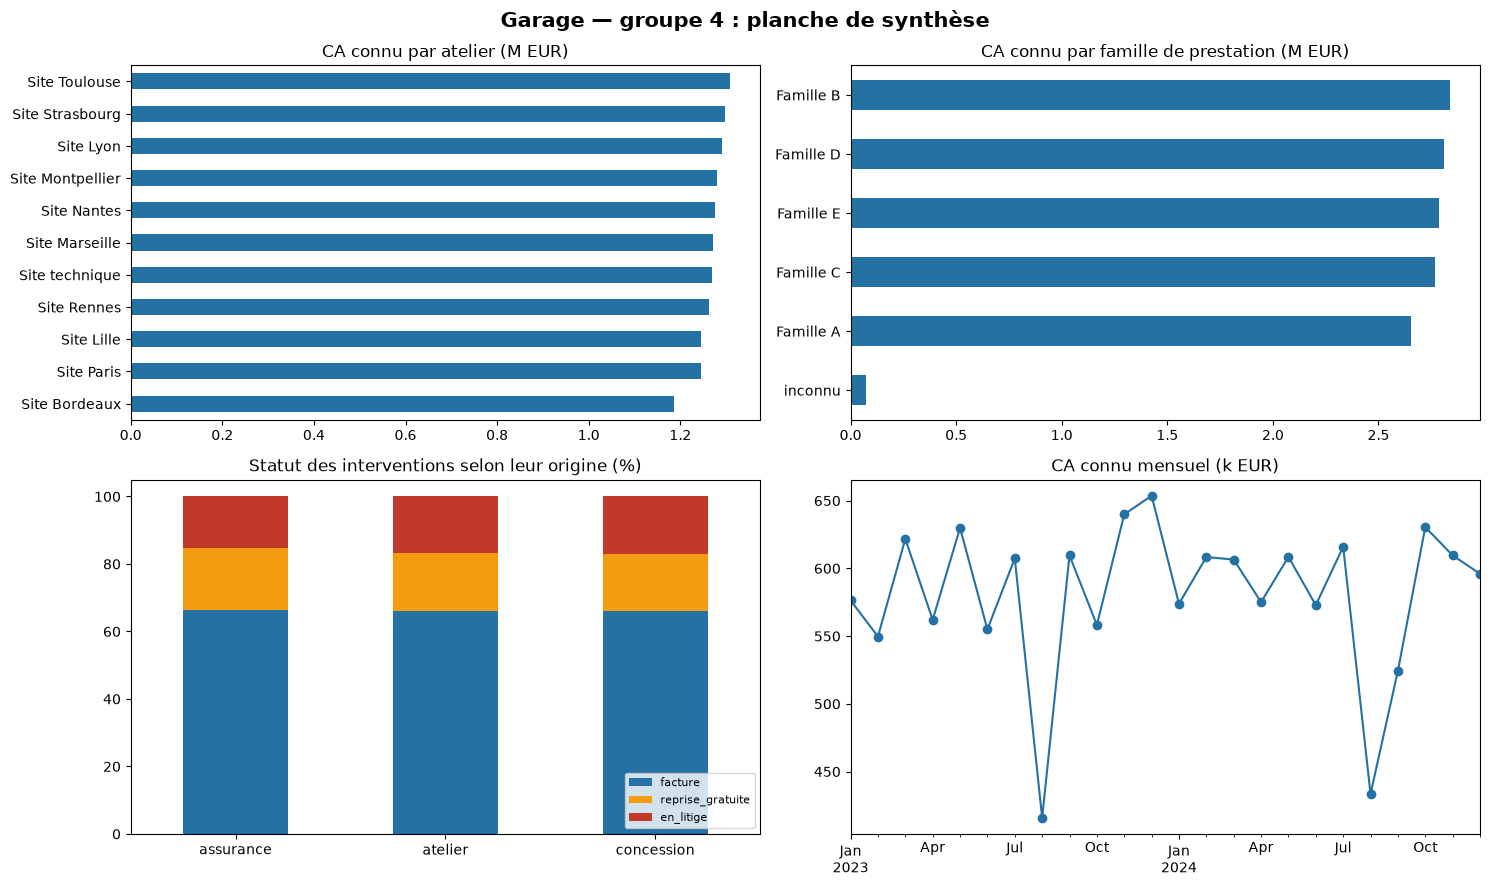

In [6]:
# Chargement du jeu final et contrôles de cohérence
# TODO
import matplotlib.pyplot as plt

fact = pd.read_parquet(STAR_DIR / 'fact_interventions.parquet')
dim_atelier = pd.read_parquet(STAR_DIR / 'dim_atelier.parquet')
dim_prestation = pd.read_parquet(STAR_DIR / 'dim_prestation.parquet')
dim_date = pd.read_parquet(STAR_DIR / 'dim_date.parquet')

# Contrôles de cohérence
assert fact['id_intervention'].is_unique, 'identifiant d\'intervention dupliqué'
assert (fact['duree_heures'].dropna() > 0).all(), 'durée négative restante'
assert (fact['km_vehicule'].dropna() < 999_999).all(), 'kilométrage sentinelle restant'
assert set(fact['statut']) == {'facture', 'reprise_gratuite', 'en_litige'}
assert set(fact['origine']) == {'atelier', 'concession', 'assurance'}
print('OK — contrôles de cohérence passés')
print('Structure : 1 table de faits', fact.shape, '+ 4 dimensions')

# Indicateurs
enriched = (fact.merge(dim_atelier[['id_atelier', 'nom_site']], on='id_atelier', how='left',
                       validate='many_to_one')
                .merge(dim_prestation[['id_prestation', 'famille']], on='id_prestation', how='left',
                       validate='many_to_one')
                .merge(dim_date[['cle_date', 'date']], on='cle_date', how='left', validate='many_to_one'))
known = enriched[~enriched['montant_manquant']]
indicators = {
    'interventions': len(fact),
    'CA connu (EUR)': round(known['montant_facture_eur'].sum(), 2),
    'montant médian (EUR)': round(known['montant_facture_eur'].median(), 2),
    'part de montants manquants': f"{fact['montant_manquant'].mean():.1%}",
    'taux de reprise gratuite': f"{(fact['statut'] == 'reprise_gratuite').mean():.1%}",
    'taux de litige': f"{(fact['statut'] == 'en_litige').mean():.1%}",
}
for label, value in indicators.items():
    print(f'  {label:<28} {value}')

by_site = (enriched.groupby('nom_site')
           .agg(ca=('montant_facture_eur', 'sum'), interventions=('id_intervention', 'count'),
                taux_litige=('statut', lambda s: (s == 'en_litige').mean()),
                taux_reprise=('statut', lambda s: (s == 'reprise_gratuite').mean()))
           .sort_values('ca', ascending=False))
print()
print(by_site.round(3))

# Planche de visualisation
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
(by_site['ca'] / 1e6).sort_values().plot.barh(ax=axes[0, 0], color='#2471A3')
axes[0, 0].set_title("CA connu par atelier (M EUR)")
axes[0, 0].set_ylabel('')
(known.groupby('famille')['montant_facture_eur'].sum() / 1e6).sort_values().plot.barh(
    ax=axes[0, 1], color='#2471A3')
axes[0, 1].set_title("CA connu par famille de prestation (M EUR)")
axes[0, 1].set_ylabel('')
status_by_origin = pd.crosstab(enriched['origine'], enriched['statut'], normalize='index') * 100
status_by_origin[['facture', 'reprise_gratuite', 'en_litige']].plot.bar(
    ax=axes[1, 0], stacked=True, color=['#2471A3', '#F39C12', '#C0392B'], rot=0)
axes[1, 0].set_title('Statut des interventions selon leur origine (%)')
axes[1, 0].set_xlabel('')
axes[1, 0].legend(loc='lower right', fontsize=8)
(known.set_index('date')['montant_facture_eur'].resample('ME').sum() / 1e3).plot(
    ax=axes[1, 1], marker='o', color='#2471A3')
axes[1, 1].set_title('CA connu mensuel (k EUR)')
axes[1, 1].set_xlabel('')
fig.suptitle('Garage — groupe 4 : planche de synthèse', fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(ROOT / 'docs' / 'garage_planche.png', dpi=130, bbox_inches='tight')
plt.show()

---
## 6. Contrôle avant dépôt

La cellule suivante vérifie que votre rendu est complet. Exécutez-la avant de déposer.

Le dépôt est attendu le **jour 5 à 13 h 30**, avant la reprise de l'après-midi : votre
composant PySpark se termine le matin même. Prévoyez trente minutes pour la mise en forme,
pas cinq.

In [7]:
checks = {
    'requirements.txt présent': (ROOT / 'requirements.txt').exists(),
    'README.md présent': (ROOT / 'README.md').exists(),
    'dossier src/ non vide': (ROOT / 'src').exists() and any((ROOT / 'src').glob('*.py')),
    'jeu final produit': (any(PROCESSED_DIR.glob('*.parquet'))
                          or any(PROCESSED_DIR.glob('*.csv'))
                          or any((PROCESSED_DIR / 'garage' / 'star').glob('*.parquet'))),
    'note méthodologique': any(ROOT.glob('note_methodologique.*')),
    'support de soutenance': any(ROOT.glob('soutenance.*')),
}

width = max(len(label) for label in checks)
for label, is_ok in checks.items():
    print(f"{label:<{width}}  {'OK' if is_ok else 'MANQUANT'}")

if all(checks.values()):
    print('\nRendu complet.')
else:
    print('\nIl manque des éléments listés ci-dessus.')

requirements.txt présent  OK
README.md présent         OK
dossier src/ non vide     OK
jeu final produit         OK
note méthodologique       MANQUANT
support de soutenance     MANQUANT

Il manque des éléments listés ci-dessus.


---
## 7. Préparation aux questions

Rédigez votre réponse à chacune de ces questions **avant** la soutenance. Elles seront
posées dans une formulation proche.

1. Pourquoi avoir imputé cette colonne de cette façon plutôt qu'autrement ?
2. Vous avez écarté un certain pourcentage de lignes. Comment savez-vous qu'il ne
   s'agissait pas d'observations légitimes ?
3. Combien de colonnes votre encodage a-t-il produit ? Quelles conséquences ?
4. À partir de quel volume votre pipeline Pandas cesserait-il de fonctionner ?
5. Si je vous fournis demain un nouveau fichier source au même format, que faut-il faire ?
6. Montrez-moi la ligne de code qui traite ce cas particulier et expliquez-la.
7. Quelle est la principale limite de votre jeu de données final ?

> **Chaque membre du groupe doit pouvoir répondre sur l'intégralité du travail**, y compris
> les parties qu'il n'a pas présentées. Les questions sont posées individuellement.

### Nos réponses

**1. Pourquoi avoir imputé cette colonne de cette façon plutôt qu'autrement ?**

Nous n'avons imputé que deux colonnes, et **volontairement pas le montant** :

- **`age` (clients) : médiane par segment**, après avoir mis à vide les âges impossibles
  (< 18 ou > 100, dont les codes 999), soit 251 valeurs imputées au total. La médiane plutôt
  que la moyenne, parce que la moyenne brute (≈ 48 ans) est tirée vers le haut par les 999 ;
  par segment, parce qu'un particulier, un professionnel et une association n'ont pas le
  même profil. L'indicateur `age_imputee` permet d'exclure ces lignes d'une analyse d'âge.
- **`cout_reference_eur` (prestations) : médiane de la sous-famille**, à défaut de la famille.
  Deux prestations seulement ; des prestations d'une même sous-famille ont des coûts
  comparables. Indicateur `cout_imputee`.
- **`montant_facture_eur` : pas d'imputation** (1 333 manquants, 8 %). C'est la mesure
  principale : imputer la médiane (≈ 894 €) ajouterait ≈ 1,2 M€ de CA fictif. Le taux de
  manquants est le même quel que soit le statut ou l'origine (absence au hasard), et le
  montant n'est corrélé ni à la durée ni au coût de référence (r ≈ 0) : aucune imputation
  conditionnelle n'aurait été défendable. On garde le vide et l'indicateur `montant_manquant`.

**2. Vous avez écarté un certain pourcentage de lignes. Comment savez-vous qu'il ne
s'agissait pas d'observations légitimes ?**

Nous avons écarté **490 interventions sur 17 150 (2,9 %)**, pour deux raisons seulement :

- **150 doublons stricts** : lignes identiques sur *toutes* les colonnes, y compris
  `id_intervention`. Deux interventions réelles ne partagent pas le même identifiant :
  c'est une double extraction, pas une seconde intervention. Le dédoublonnage est fait
  **après** normalisation du texte, pour ne pas laisser passer « FACTURE » / « facture ».
- **340 lignes sans date** : l'intervention a peut-être eu lieu, mais elle est
  inexploitable dans le modèle (pas de `cle_date`, donc pas de rattachement à la
  dimension temps). Elles représentent 2 % du jeu et sont réparties au hasard entre
  ateliers, statuts et origines : leur retrait ne déforme pas les comparaisons.

Tout le reste a été **conservé** : durées négatives et kilométrages 999 999 mis à vide sans
supprimer la ligne, durées de 24 h simplement signalées, `PRS9999` rattachée à un membre
« inconnu ». Le journal `journal_nettoyage_garage.json` trace chaque compteur.

**3. Combien de colonnes votre encodage a-t-il produit ? Quelles conséquences ?**

**Aucune** : nous n'avons pas fait d'encodage one-hot, et c'est un choix. Le jeu final est
un modèle en étoile destiné à un outil de BI, qui filtre et regroupe directement sur des
libellés. La table de faits garde 13 colonnes ; `origine` et `statut` restent des colonnes
texte à 3 modalités propres (contre 9 avant normalisation).

Un one-hot aurait produit 3 + 3 = 6 colonnes pour `origine` et `statut`, et **95 colonnes**
pour `id_prestation` (96 avec le membre inconnu), presque toutes à zéro : une table creuse,
illisible en BI, et dont le schéma changerait à chaque nouvelle prestation au catalogue.
L'encodage relève de l'étape de modélisation, si un modèle prédictif est construit plus
tard ; il se fera alors sur cette base propre.

**4. À partir de quel volume votre pipeline Pandas cesserait-il de fonctionner ?**

Il faut distinguer **mémoire** et **temps** :

- **Mémoire** : le jeu nettoyé occupe ≈ 132 octets par intervention. Avec la RAM disponible
  (≈ 10 Go) et un facteur 3 de mémoire de travail, la limite est d'environ **22 à
  27 millions d'interventions** selon la machine, soit des siècles d'activité au rythme
  actuel (≈ 8 300 par an).
- **Temps** : c'est la vraie limite. Le nettoyage Pandas prend ≈ 13 s pour 1,7 million de
  lignes, contre ≈ 1,8 s en Spark, à cause du parsing des dates en `format='mixed'`, qui
  infère le format ligne par ligne. Le pipeline Pandas ne « casse » donc pas, mais il
  devient le goulot d'étranglement au-delà de quelques centaines de milliers de lignes.
  C'est pour cela que le nettoyage des interventions a été porté sur Spark.

**5. Si je vous fournis demain un nouveau fichier source au même format, que faut-il
faire ?**

1. Déposer les fichiers dans `data/projets/groupe_04_garage/` (ou passer
   `--input` à `spark-submit src/garage_spark.py`).
2. Réexécuter le notebook : les fonctions de `src/garage.py` ne contiennent aucune valeur
   codée en dur liée à ce fichier (médianes recalculées sur les nouvelles données, membres
   « inconnu » ajoutés automatiquement pour toute prestation absente du catalogue).
3. **Relire le journal de nettoyage** avant de publier : un compteur qui explose signale une
   anomalie nouvelle. Exemple : un sixième format de date non reconnu serait converti en
   vide (`errors='coerce'`) et apparaîtrait dans `lignes_sans_date_supprimees`.
4. Les contrôles s'exécutent seuls : idempotence, intégrité référentielle
   (`check_referential_integrity`), assertions de cohérence de la section 5, et égalité
   Spark / Pandas sur le nombre de lignes et le CA.

**6. Montrez-moi la ligne de code qui traite ce cas particulier et expliquez-la.**

Exemple du **kilométrage sentinelle**, `src/garage.py`, lignes 65-66 :

```python
df['km_inconnu'] = (df['km_vehicule'].isna() | (df['km_vehicule'] == KM_SENTINEL)).astype(bool)
df['km_vehicule'] = df['km_vehicule'].astype('Float64').mask(df['km_vehicule'] == KM_SENTINEL)
```

La première ligne crée l'indicateur **avant** de modifier la valeur, sinon l'information
serait perdue. La seconde remplace 999 999 par une valeur manquante (`mask`) ; le passage en
`Float64` (nullable) permet de stocker ce vide sans transformer la colonne en `object`.
`KM_SENTINEL` est une constante nommée en tête de module, avec sa justification en
commentaire. Le code est idempotent : au second passage, il n'y a plus de 999 999 et
l'indicateur est reconstruit à l'identique à partir des vides.

Autre exemple, le **montant « nan EUR »**, lignes 33-35 : `disguised` repère ce manquant
déguisé en texte, que `parse_price` transforme en vide ; sans ce test, il aurait été compté
à tort parmi les montants textuels convertis.

**7. Quelle est la principale limite de votre jeu de données final ?**

**Le chiffre d'affaires est sous-estimé d'environ 8 %** : 1 333 interventions n'ont pas de
montant et n'ont pas été imputées. Tous les CA affichés (13,93 M€ au total) sont des CA
*connus*. Comme l'absence est répartie au hasard entre ateliers, familles, statuts et
origines, les **comparaisons** restent valides, mais pas les **totaux absolus**.

Les autres limites sont listées en section 3 : `date_creation` des clients non fiable
(9,8 % d'interventions antérieures à la création du client), statut incertain du « Site
technique » d'Orléans, et absence de lien entre montant et prestation qui empêche de
détecter une facture anormale.
